# Design an FIR filter

#### A sensor produces a signal containing three useful frequencies and one unwanted frequency:
    sampling frequency = 200 Hz
    signal duration = 3 seconds
    useful frequencies = 4, 10 and 15 Hz
    unwanted interference  = 40 Hz
objective:

Remove 40 Hz while preserving the useful components

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

#sampling parameters
fs, duration = 200, 3
N = fs * duration

t = np.arange(N) / fs

#Original Useful Signal
clean = ( np.sin(2 * np.pi * 4 * t) + np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 15 * t))

#Unwanted Interference
noise = 1.5 * np.sin(2 * np.pi * 40 * t)

#Measured Signal
x = clean + noise

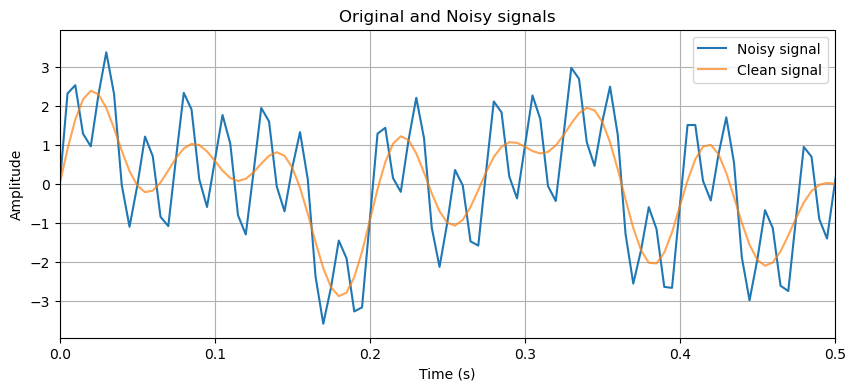

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(t, x, label = "Noisy signal")
plt.plot(t, clean, label = "Clean signal", alpha = 0.7)
plt.xlim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original and Noisy signals")
plt.legend()
plt.grid(True)
plt.show()

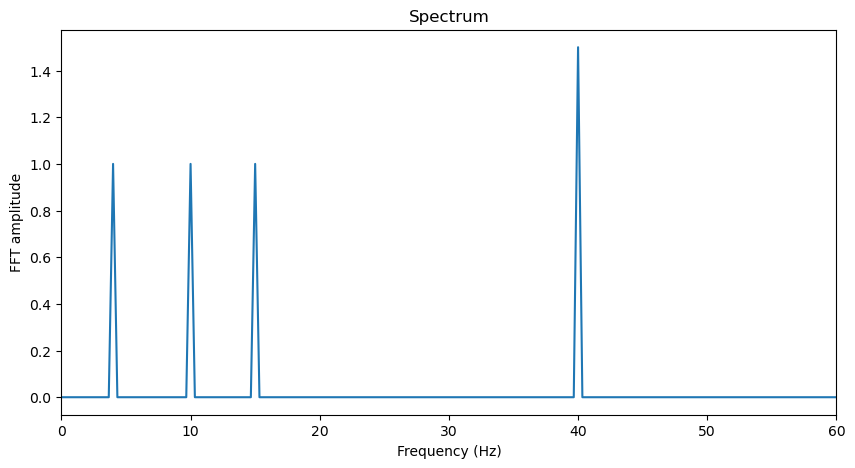

In [4]:
freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_fft = np.abs(np.fft.rfft(x)) / N
amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft)
plt.xlim(0, 60)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT amplitude")
plt.title("Spectrum")
plt.show()

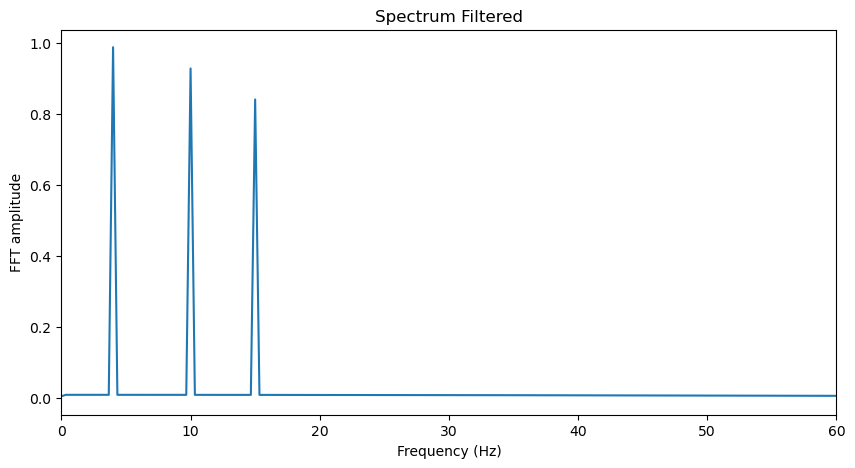

In [5]:
#Adding Zero at Unwanted Frequency
theta = 2 * np.pi * 40 / fs
b1 = np.array([1, -2 * np.cos(theta), 1])
b1 = 1/sum(b1) * b1
fir_out = lfilter(b1, [1], x)
amplitude_fir_fft = np.abs(np.fft.rfft(fir_out)) / N
amplitude_fir_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fir_fft)
plt.xlim(0, 60)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT amplitude")
plt.title("Spectrum Filtered")
plt.show()

### two requirements:
    - The gain of every frequency between 0 and 15 Hz must remain between 0.95 and 1.05
    - The gain at 40 Hz must be zero

passband_error: 15.753532911702905 %


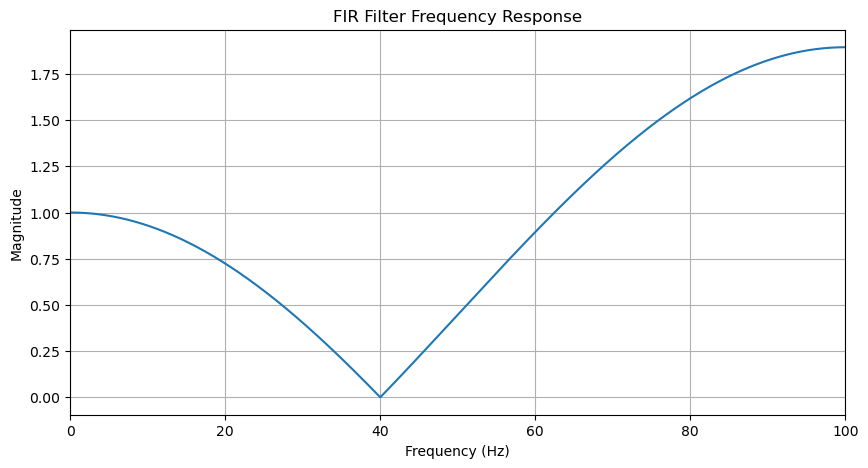

In [9]:
f, H = freqz(b1, [1], worN = 2048, fs=fs)
magnitude = np.abs(H)
passband = f <= 15
passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
print("passband_error:", passband_error, "%")

plt.figure(figsize=(10, 5))
plt.plot(f, magnitude)
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FIR Filter Frequency Response")
plt.grid(True)
plt.show()

#### Now the task is to improve the FIR filter while keeping the 40 Hz interference removed
    we start by adding zero at Nyquist frequency(100Hz) because original filter amplifies higher frequencies

In [12]:
b2 = np.convolve(b1, [1, 1])
b2 = b2  / sum(b2) 
print("newfilter_coefficients:", b2)

newfilter_coefficients: [0.3618034 0.1381966 0.1381966 0.3618034]


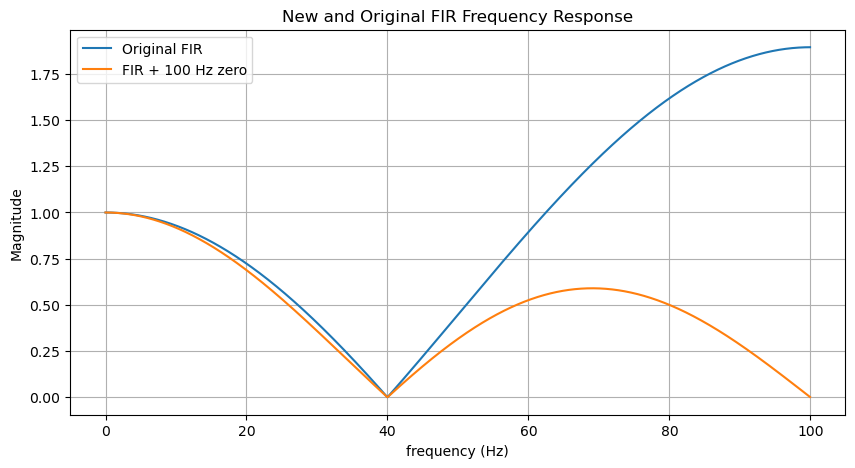

In [17]:
f, H1 = freqz(b1, [1], worN = 2048, fs=fs)
_, H2 = freqz(b2, [1], worN = 2048, fs=fs)
magnitude1 = np.abs(H1)
magnitude2 = np.abs(H2)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude1, label = "Original FIR")
plt.plot(f, magnitude2, label = "FIR + 100 Hz zero")
plt.xlabel("frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("New and Original FIR Frequency Response")
plt.grid(True)
plt.legend()
plt.show()

The new filter is better at suppressing high frequencies, but its passband performance is worse.

Between these two FIR filters, I would choose the original one if preserving 0–15 Hz was more important than suppressing high-frequency noise.

However, neither filter fully meets our design requirements, so further improvements are needed.